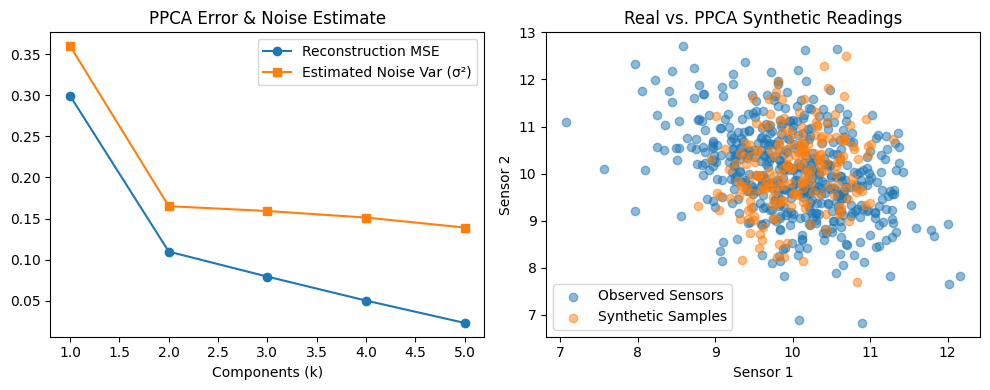

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

rng = np.random.default_rng(42)
n_samples, n_features = 500, 6
latent_true = rng.normal(size=(n_samples, 2))
W_true = rng.normal(size=(2, n_features))
noise = rng.normal(0, 0.4, size=(n_samples, n_features))
X = latent_true @ W_true + 10.0 + noise

ks = range(1, n_features)
mse_list, noise_vars = [], []
for k in ks:
    ppca = PCA(n_components=k).fit(X)
    Z = ppca.transform(X)
    X_rec = ppca.inverse_transform(Z)
    mse_list.append(np.mean((X - X_rec) ** 2))
    noise_vars.append(ppca.noise_variance_)

best_ppca = PCA(n_components=2).fit(X)
synth_z = rng.normal(size=(200, 2))
synth_X = best_ppca.inverse_transform(synth_z) + rng.normal(0, np.sqrt(best_ppca.noise_variance_), size=(200, n_features))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(list(ks), mse_list, marker="o", label="Reconstruction MSE")
axes[0].plot(list(ks), noise_vars, marker="s", label="Estimated Noise Var (σ²)")
axes[0].set_xlabel("Components (k)"); axes[0].set_title("PPCA Error & Noise Estimate"); axes[0].legend()

axes[1].scatter(X[:, 0], X[:, 1], alpha=0.5, label="Observed Sensors")
axes[1].scatter(synth_X[:, 0], synth_X[:, 1], alpha=0.5, label="Synthetic Samples")
axes[1].set_xlabel("Sensor 1"); axes[1].set_ylabel("Sensor 2")
axes[1].set_title("Real vs. PPCA Synthetic Readings"); axes[1].legend()
plt.tight_layout(); plt.show()